# Week 5 - Support Vector Machines, the Kernel Trick, and SVM Regularization

Weeks 1-4 all used the e-commerce dataset. The Milestone One guidelines require at least two datasets, and SVMs happen to work in two very different regimes, so this week I use two of my three capstone datasets:

1. **E-commerce (`ecommerce_data.csv`)**: predict whether an order is profitable (`Profit > 0`), the same target as Week 4. That makes the SVM directly comparable to my Week 4 logistic regression baseline. This is a low-dimensional, dense feature space (29 columns), which is where the **kernel trick** is supposed to matter.
2. **Amazon reviews (`amazon_review_data.csv`)**: predict whether a review is *negative* (rating of 1-2) from its text. This is a very high-dimensional, sparse feature space (thousands of TF-IDF columns), where a plain linear SVM is the textbook choice. It is also my first use of the review data, and it ties to the capstone question about whether review sentiment carries signal.

Both targets are imbalanced (about 19% unprofitable orders, about 12% negative reviews), so besides accuracy and ROC AUC I track **F1 on the minority class**, which is the metric my capstone proposal committed to.

In [3]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, make_scorer,
                             confusion_matrix, classification_report)
from sklearn.datasets import make_circles

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(name, y_true, scores, preds, neg_label):
    # scores: any score where higher = class 1 (decision_function or probability)
    return {"model": name,
            "accuracy": accuracy_score(y_true, preds),
            "roc_auc": roc_auc_score(y_true, scores),
            "f1_minority": f1_score(y_true, preds, pos_label=neg_label)}

## Part A - E-commerce: is this order profitable?

### A1. Data, features, and the Week 4 baseline

Same 29 features and the same stratified split as Week 4. SVMs are distance/margin based, so unlike trees they need scaled features; the scaler is fit on the training split only.

In [4]:
df = pd.read_csv("ecommerce_data.csv")
numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]

X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True).astype(float)
y = (df["Profit"] > 0).astype(int).values   # 1 = profitable, 0 = unprofitable (minority class)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

print(X.shape, f"profitable share: {y.mean():.1%}")

# Week 4 baseline: cross-validated L2 logistic regression
logit = LogisticRegressionCV(Cs=np.logspace(-2, 3, 50), cv=5, scoring="roc_auc", max_iter=5000).fit(Xs_train, y_train)
results = [evaluate("Logistic regression (Week 4)", y_test, logit.decision_function(Xs_test), logit.predict(Xs_test), neg_label=0)]
pd.DataFrame(results).round(3)

(3312, 29) profitable share: 80.7%


,model,accuracy,roc_auc,f1_minority
0,Logistic regression (Week 4),0.925,0.976,0.804


### A2. The kernel trick - a toy picture first

A linear SVM can only draw a straight boundary. The kernel trick lets an SVM behave as if the data had been lifted into a much higher-dimensional space, without ever computing that mapping: it only needs the kernel function $K(x, x')$ between pairs of points. The RBF kernel $K(x,x') = \exp(-\gamma \lVert x - x' \rVert^2)$ corresponds to an infinite-dimensional feature space. Concentric circles are the classic case where this matters. This cell is a toy illustration only, not project data.

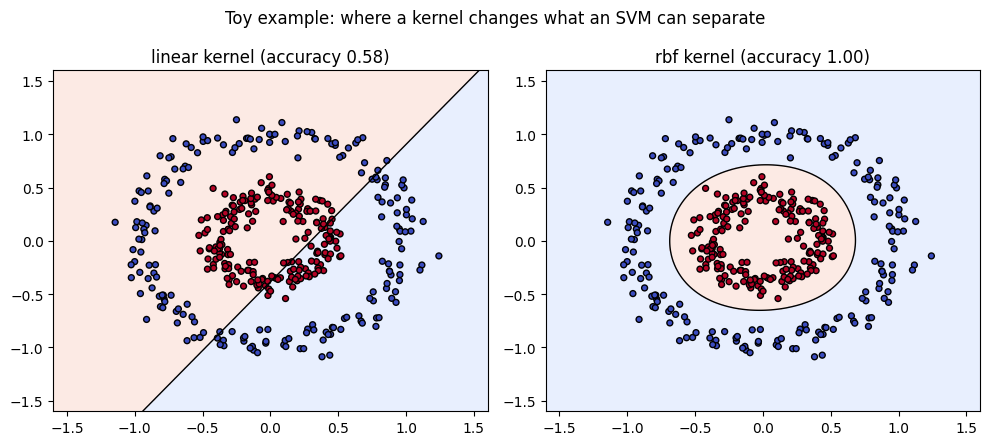

In [5]:
Xc, yc = make_circles(n_samples=400, factor=0.4, noise=0.08, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
gx, gy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    m = SVC(kernel=kernel, C=1, gamma="scale").fit(Xc, yc)
    Z = m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, Z > 0, alpha=0.2, cmap="coolwarm")
    ax.contour(gx, gy, Z, levels=[0], colors="k", linewidths=1)
    ax.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", edgecolor="k", s=18)
    ax.set_title(f"{kernel} kernel (accuracy {m.score(Xc, yc):.2f})")
plt.suptitle("Toy example: where a kernel changes what an SVM can separate")
plt.tight_layout(); plt.show()

### A3. Does the kernel matter on the real e-commerce data?

To see the decision boundary, I fit each kernel on just two features, `Discount` and log-transformed `Sales` (log only so the heavy right tail doesn't squash the plot). This 2-D picture is for visualization only; every other number in this notebook uses all 29 features.

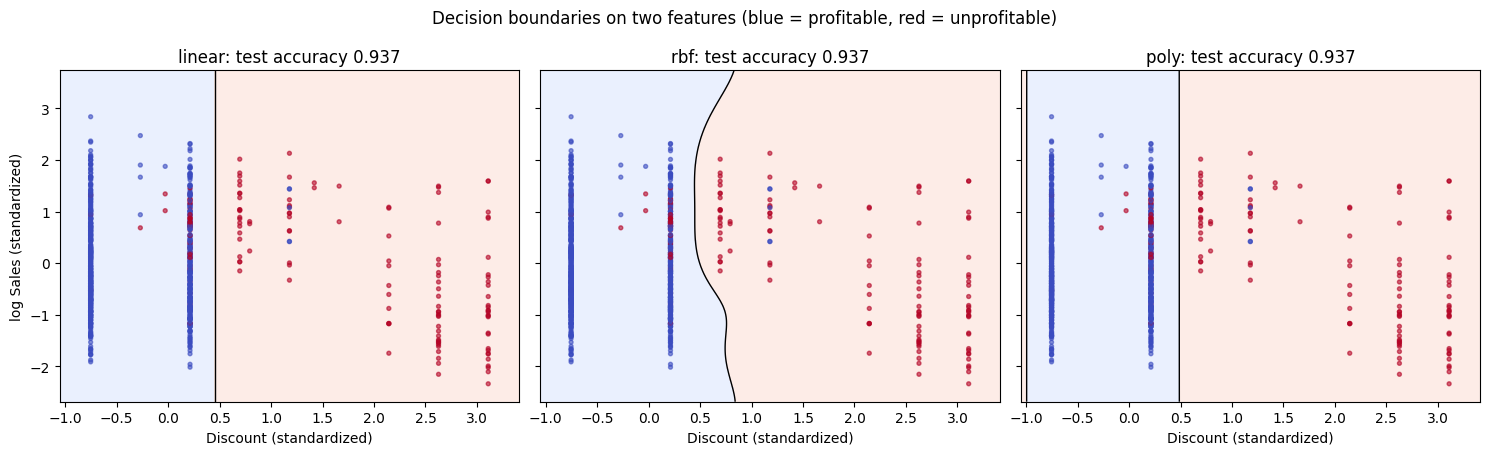

Discount
(-0.01, 0.0]    0.994
(0.0, 0.1]      0.929
(0.1, 0.2]      0.851
(0.2, 0.3]      0.015
(0.3, 0.5]      0.097
(0.5, 1.0]      0.000
Name: share profitable, dtype: float64


In [6]:
d2 = pd.DataFrame({"Discount": df["Discount"], "log_Sales": np.log1p(df["Sales"])})
d2_tr, d2_te, y2_tr, y2_te = train_test_split(d2, y, test_size=0.25, random_state=42, stratify=y)
s2 = StandardScaler().fit(d2_tr)
P_tr, P_te = s2.transform(d2_tr), s2.transform(d2_te)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
gx, gy = np.meshgrid(np.linspace(P_tr[:, 0].min()-.3, P_tr[:, 0].max()+.3, 300),
                     np.linspace(P_tr[:, 1].min()-.3, P_tr[:, 1].max()+.3, 300))
specs = [("linear", {}), ("rbf", {"gamma": 1.0}), ("poly", {"degree": 3, "coef0": 1, "gamma": "scale"})]
for ax, (kernel, kw) in zip(axes, specs):
    m = SVC(kernel=kernel, C=1, **kw).fit(P_tr, y2_tr)
    Z = m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, Z > 0, alpha=0.18, cmap="coolwarm_r")
    ax.contour(gx, gy, Z, levels=[0], colors="k", linewidths=1)
    ax.scatter(P_te[:, 0], P_te[:, 1], c=y2_te, cmap="coolwarm_r", s=8, alpha=0.6)
    ax.set_title(f"{kernel}: test accuracy {m.score(P_te, y2_te):.3f}")
    ax.set_xlabel("Discount (standardized)")
axes[0].set_ylabel("log Sales (standardized)")
plt.suptitle("Decision boundaries on two features (blue = profitable, red = unprofitable)")
plt.tight_layout(); plt.show()

print(df.groupby(pd.cut(df["Discount"], [-0.01, 0, 0.1, 0.2, 0.3, 0.5, 1]), observed=True)["Profit"]
        .agg(lambda s: (s > 0).mean()).round(3).rename("share profitable"))

### A4. Feature scaling matters for SVMs

Week 4's lesson (scale your features) is even more important here, because an SVM's margin is defined by distances between points. Same model, same split, with and without scaling:

In [7]:
rows = []
for kernel in ["linear", "rbf"]:
    for label, (a, b) in {"unscaled": (X_train.values, X_test.values), "scaled": (Xs_train, Xs_test)}.items():
        m = SVC(kernel=kernel, C=1, max_iter=500000).fit(a, y_train)
        rows.append({"kernel": kernel, "features": label,
                     "accuracy": accuracy_score(y_test, m.predict(b)),
                     "roc_auc": roc_auc_score(y_test, m.decision_function(b))})
pd.DataFrame(rows).round(3)

c:\Users\peace\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=500000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


,kernel,features,accuracy,roc_auc
0,linear,unscaled,0.680,0.938
1,linear,scaled,0.926,0.962
2,rbf,unscaled,0.807,0.768
3,rbf,scaled,0.931,0.956


### A5. Tuning the regularization strength C and the kernel parameters

- **C** is the inverse regularization strength: small C = wide margin, tolerate misclassified points (high bias); large C = punish every training error, narrow margin (high variance / overfitting risk).
- **gamma** (RBF) controls how far one point's influence reaches: small gamma = smooth, nearly linear boundary; large gamma = wiggly boundary that hugs individual points.
- **degree / coef0** (polynomial) control the polynomial's flexibility.

I tune with 5-fold stratified cross-validation on the training set only, scoring ROC AUC (refit metric) while also recording F1 on the unprofitable class. The test set is touched once, at the end.

In [8]:
f1_unprofitable = make_scorer(f1_score, pos_label=0)
scoring = {"auc": "roc_auc", "f1_neg": f1_unprofitable}

grids = {
    "linear": {"C": [0.01, 0.1, 1, 10, 100]},
    "rbf":    {"C": [0.1, 1, 10, 100, 1000, 10000], "gamma": [0.0001, 0.001, 0.01, 0.03, 0.1, 0.3]},
    "poly":   {"C": [0.1, 1, 10, 100], "degree": [2, 3], "coef0": [1], "gamma": ["scale"]},
}
searches, t0 = {}, time.time()
for kernel, grid in grids.items():
    searches[kernel] = GridSearchCV(SVC(kernel=kernel), grid, scoring=scoring, refit="auc", cv=cv5, n_jobs=-1).fit(Xs_train, y_train)
    gs = searches[kernel]
    print(f"{kernel:6s} best params {gs.best_params_}  CV AUC {gs.best_score_:.4f}")
print(f"grid search time: {time.time() - t0:.0f}s")

for kernel, gs in searches.items():
    m = gs.best_estimator_
    results.append(evaluate(f"SVM {kernel} (tuned)", y_test, m.decision_function(Xs_test), m.predict(Xs_test), neg_label=0))
    results[-1]["train_accuracy"] = accuracy_score(y_train, m.predict(Xs_train))
    results[-1]["n_support_vectors"] = int(m.n_support_.sum())
ecom_results = pd.DataFrame(results).set_index("model")
ecom_results.round(3)

linear best params {'C': 1}  CV AUC 0.9744
rbf    best params {'C': 1000, 'gamma': 0.001}  CV AUC 0.9745
poly   best params {'C': 1, 'coef0': 1, 'degree': 2, 'gamma': 'scale'}  CV AUC 0.9696
grid search time: 25s


,accuracy,roc_auc,f1_minority,train_accuracy,n_support_vectors
model,,,,,
Logistic regression (Week 4),0.925,0.976,0.804,NaN,NaN
SVM linear (tuned),0.926,0.962,0.812,0.940,390.0
SVM rbf (tuned),0.935,0.965,0.825,0.954,333.0
SVM poly (tuned),0.937,0.961,0.830,0.952,389.0


### A6. Visualizing the bias-variance trade-off in C and gamma

Left: the full RBF tuning surface (cross-validated AUC for every C/gamma pair). Middle and right: training vs. cross-validated AUC as one parameter is swept with the other held at its best value. Where the two curves separate, the model is memorizing the training data.

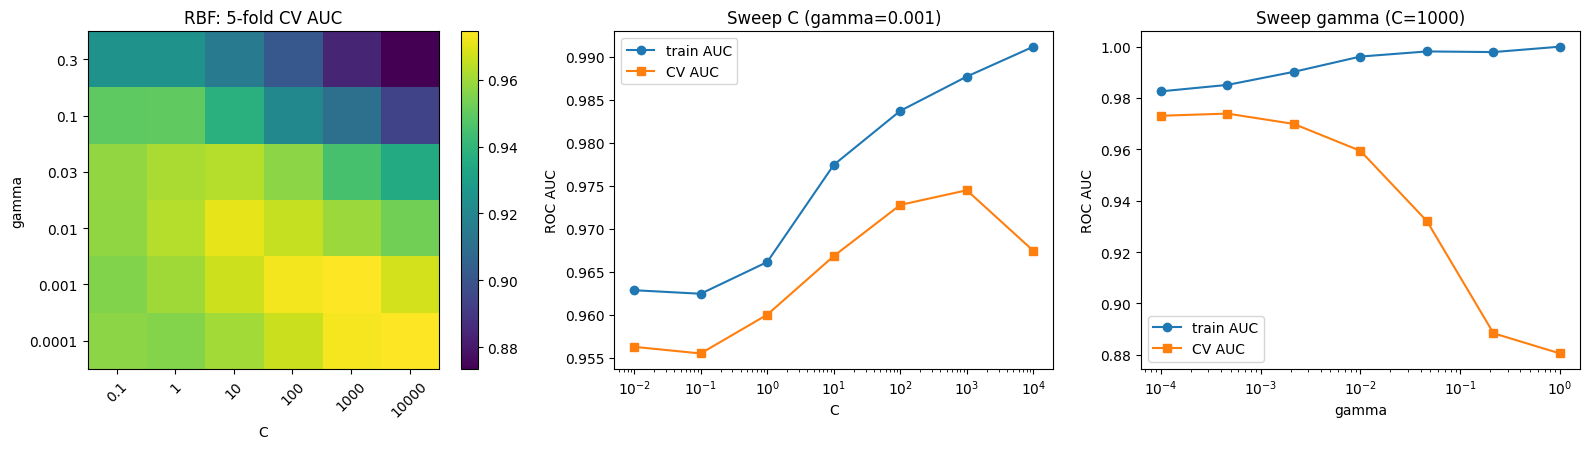

Support vectors vs C (RBF): {'0.01': 959, '0.1': 972, '1': 781, '10': 491, '100': 362, '1000': 333, '10000': 307}


In [7]:
rbf_gs = searches["rbf"]
res = pd.DataFrame(rbf_gs.cv_results_)
heat = res.pivot_table(index="param_gamma", columns="param_C", values="mean_test_auc")
best_C, best_gamma = rbf_gs.best_params_["C"], rbf_gs.best_params_["gamma"]

C_range = np.logspace(-2, 4, 7)
tr_C, va_C = validation_curve(SVC(kernel="rbf", gamma=best_gamma), Xs_train, y_train, param_name="C",
                              param_range=C_range, scoring="roc_auc", cv=cv5, n_jobs=-1)
g_range = np.logspace(-4, 0, 7)
tr_g, va_g = validation_curve(SVC(kernel="rbf", C=best_C), Xs_train, y_train, param_name="gamma",
                              param_range=g_range, scoring="roc_auc", cv=cv5, n_jobs=-1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
im = axes[0].imshow(heat.values, aspect="auto", cmap="viridis", origin="lower")
axes[0].set_xticks(range(heat.shape[1])); axes[0].set_xticklabels([f"{c:g}" for c in heat.columns], rotation=45)
axes[0].set_yticks(range(heat.shape[0])); axes[0].set_yticklabels([f"{g:g}" for g in heat.index])
axes[0].set_xlabel("C"); axes[0].set_ylabel("gamma"); axes[0].set_title("RBF: 5-fold CV AUC")
plt.colorbar(im, ax=axes[0])
for ax, rng, tr_s, va_s, xl, title in [(axes[1], C_range, tr_C, va_C, "C", f"Sweep C (gamma={best_gamma:g})"),
                                       (axes[2], g_range, tr_g, va_g, "gamma", f"Sweep gamma (C={best_C:g})")]:
    ax.semilogx(rng, tr_s.mean(1), "o-", label="train AUC")
    ax.semilogx(rng, va_s.mean(1), "s-", label="CV AUC")
    ax.set_xlabel(xl); ax.set_ylabel("ROC AUC"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

sv = [(c, SVC(kernel="rbf", gamma=best_gamma, C=c).fit(Xs_train, y_train).n_support_.sum()) for c in C_range]
print("Support vectors vs C (RBF):", {f"{c:g}": int(n) for c, n in sv})

## Part B - Amazon reviews: is this review negative?

### B1. Build the label

I keep ratings of 1-2 as **negative** (the class of interest, label 1) and 4-5 as positive, and drop the ambiguous 3-star reviews. Rating is used only to build the label; it is never a feature (my capstone proposal's first Amazon model scored a perfect 1.0 because sentiment leaked in from rating).

In [9]:
a = pd.read_csv("amazon_review_data.csv")
a = a[a["rating"] != 3].copy()
a["negative"] = (a["rating"] <= 2).astype(int)
a["title"] = a["title"].fillna(""); a["text"] = a["text"].fillna("")
a["full_text"] = a["title"] + ". " + a["text"]

print(a.shape, a["negative"].value_counts().to_dict(), f"-> {a['negative'].mean():.1%} negative (about 1 : {(1-a['negative'].mean())/a['negative'].mean():.0f})")
a_train, a_test = train_test_split(a, test_size=0.25, random_state=42, stratify=a["negative"])
ya_train, ya_test = a_train["negative"].values, a_test["negative"].values

(9373, 13) {0: 8208, 1: 1165} -> 12.4% negative (about 1 : 7)


### B2. Baseline: metadata-only SVM

First, what can an SVM do *without* reading the review? Use review length, word count, title length, exclamation marks, helpful votes, and verified-purchase status (log-transformed because these are heavily skewed), with `class_weight="balanced"` so the minority class isn't ignored.

In [10]:
def meta(d):
    return pd.DataFrame({"review_len": np.log1p(d["text"].str.len()),
                         "word_count": np.log1p(d["text"].str.split().str.len()),
                         "title_len": np.log1p(d["title"].str.len()),
                         "exclaims": np.log1p(d["text"].str.count("!")),
                         "helpful": np.log1p(d["helpful_vote"].clip(lower=0)),
                         "verified": d["verified_purchase"].astype(int)})
ms = StandardScaler().fit(meta(a_train))
M_train, M_test = ms.transform(meta(a_train)), ms.transform(meta(a_test))

amazon_results = []
for kernel in ["linear", "rbf"]:
    m = SVC(kernel=kernel, C=1, class_weight="balanced").fit(M_train, ya_train)
    amazon_results.append(evaluate(f"Metadata only, {kernel} SVM", ya_test, m.decision_function(M_test), m.predict(M_test), neg_label=1))
pd.DataFrame(amazon_results).set_index("model").round(3)

,accuracy,roc_auc,f1_minority
model,,,
"Metadata only, linear SVM",0.688,0.613,0.245
"Metadata only, rbf SVM",0.603,0.629,0.263


### B3. TF-IDF text features + linear SVM

TF-IDF turns each review into a sparse vector of weighted word and bigram counts. I wrap the vectorizer and the SVM in a single `Pipeline`, so that during cross-validation the vocabulary and IDF weights are learned from each training fold only (fitting TF-IDF on all training data first would leak a little information into the validation folds). Tuning C, scored on F1 for the negative class:

In [11]:
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)
pipe = Pipeline([("tfidf", tfidf), ("svm", LinearSVC(class_weight="balanced", dual=True, max_iter=50000))])
C_grid = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
lin_gs = GridSearchCV(pipe, {"svm__C": C_grid}, scoring={"f1": "f1", "auc": "roc_auc"}, refit="f1", cv=cv5, n_jobs=-1)
lin_gs.fit(a_train["full_text"], ya_train)
print("best C:", lin_gs.best_params_, f"CV F1 (negative class): {lin_gs.best_score_:.3f}")

best_lin = lin_gs.best_estimator_
sc_te = best_lin.decision_function(a_test["full_text"]); pr_te = best_lin.predict(a_test["full_text"])
amazon_results.append(evaluate("TF-IDF + linear SVM (tuned)", ya_test, sc_te, pr_te, neg_label=1))
print(classification_report(ya_test, pr_te, target_names=["positive", "negative"]))
print(confusion_matrix(ya_test, pr_te))

best C: {'svm__C': 0.3} CV F1 (negative class): 0.697
              precision    recall  f1-score   support

    positive       0.97      0.96      0.96      2053
    negative       0.73      0.79      0.76       291

    accuracy                           0.94      2344
   macro avg       0.85      0.87      0.86      2344
weighted avg       0.94      0.94      0.94      2344

[[1968   85]
 [  62  229]]


### B4. Regularization and overfitting for the text SVM

With 8,000 features and only about 7,000 training reviews, this is a setting where the model *can* memorize the training set. Training vs. cross-validated F1 as C grows:

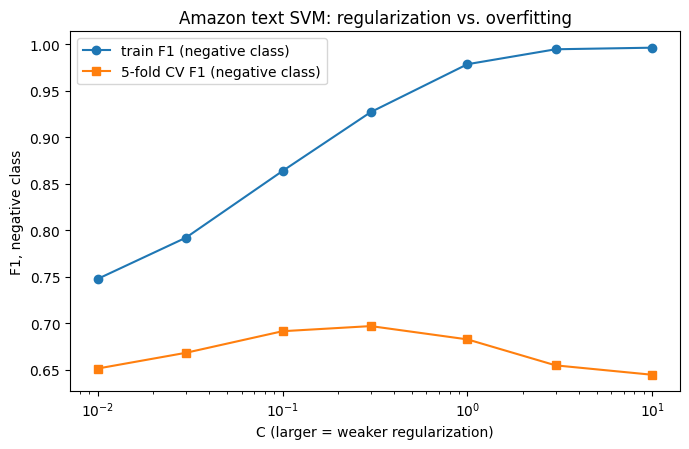

    C  train_F1  cv_F1
 0.01     0.748  0.651
 0.03     0.792  0.668
 0.10     0.864  0.692
 0.30     0.927  0.697
 1.00     0.978  0.683
 3.00     0.994  0.655
10.00     0.996  0.645


In [12]:
cvr = pd.DataFrame(lin_gs.cv_results_)
# training-fold scores via validation_curve (same pipeline, same folds)
tr_s, va_s = validation_curve(pipe, a_train["full_text"], ya_train, param_name="svm__C", param_range=C_grid,
                              scoring="f1", cv=cv5, n_jobs=-1)
plt.figure(figsize=(7, 4.6))
plt.semilogx(C_grid, tr_s.mean(1), "o-", label="train F1 (negative class)")
plt.semilogx(C_grid, va_s.mean(1), "s-", label="5-fold CV F1 (negative class)")
plt.xlabel("C (larger = weaker regularization)"); plt.ylabel("F1, negative class")
plt.title("Amazon text SVM: regularization vs. overfitting"); plt.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"C": C_grid, "train_F1": tr_s.mean(1).round(3), "cv_F1": va_s.mean(1).round(3)}).to_string(index=False))

### B5. Does the kernel trick help on text?

Text in a TF-IDF space is already extremely high-dimensional, so a linear boundary usually has plenty of room. I compare RBF and polynomial kernels (small C grids, 3-fold CV to keep runtime reasonable) against the tuned linear SVM:

In [13]:
t0 = time.time()
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
for kernel, grid in [("rbf", {"svm__C": [1, 10]}), ("poly", {"svm__C": [1, 10]})]:
    kw = {"gamma": "scale"} if kernel == "rbf" else {"gamma": "scale", "degree": 2, "coef0": 1}
    p = Pipeline([("tfidf", TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)),
                  ("svm", SVC(kernel=kernel, class_weight="balanced", **kw))])
    g = GridSearchCV(p, grid, scoring="f1", cv=cv3, n_jobs=-1).fit(a_train["full_text"], ya_train)
    est = g.best_estimator_
    amazon_results.append(evaluate(f"TF-IDF + {kernel} SVM (tuned)", ya_test,
                                   est.decision_function(a_test["full_text"]), est.predict(a_test["full_text"]), neg_label=1))
    print(kernel, g.best_params_, f"CV F1 {g.best_score_:.3f}")
print(f"time: {time.time() - t0:.0f}s")
amazon_table = pd.DataFrame(amazon_results).set_index("model")
amazon_table.round(3)

rbf {'svm__C': 1} CV F1 0.544
poly {'svm__C': 10} CV F1 0.629
time: 44s


,accuracy,roc_auc,f1_minority
model,,,
"Metadata only, linear SVM",0.688,0.613,0.245
"Metadata only, rbf SVM",0.603,0.629,0.263
TF-IDF + linear SVM (tuned),0.937,0.957,0.757
TF-IDF + rbf SVM (tuned),0.937,0.960,0.681
TF-IDF + poly SVM (tuned),0.941,0.952,0.723


### B6. What did the linear SVM learn?

A linear SVM's weights are directly interpretable: positive weights push a review toward *negative*, negative weights toward *positive*.

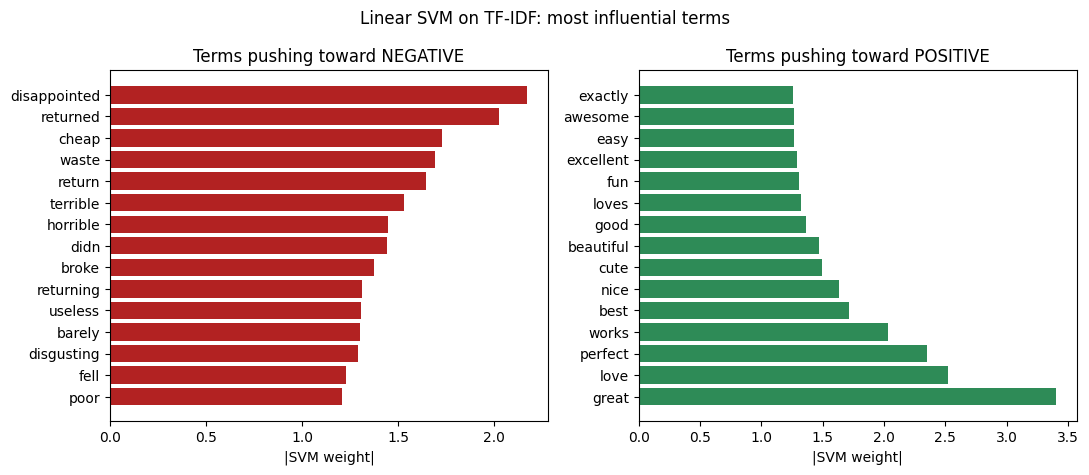

In [14]:
vec = best_lin.named_steps["tfidf"]; w = best_lin.named_steps["svm"].coef_.ravel()
terms = np.array(vec.get_feature_names_out())
top_neg = np.argsort(w)[-15:]; top_pos = np.argsort(w)[:15]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].barh(terms[top_neg], w[top_neg], color="firebrick"); axes[0].set_title("Terms pushing toward NEGATIVE")
axes[1].barh(terms[top_pos], -w[top_pos], color="seagreen"); axes[1].set_title("Terms pushing toward POSITIVE")
for ax in axes: ax.set_xlabel("|SVM weight|")
plt.suptitle("Linear SVM on TF-IDF: most influential terms"); plt.tight_layout(); plt.show()

## Summary tables

In [15]:
print("E-commerce - predicting profitable orders (minority class = unprofitable)")
display(ecom_results.round(3))
print("\nAmazon - predicting negative reviews (minority class = negative)")
display(amazon_table.round(3))

E-commerce - predicting profitable orders (minority class = unprofitable)


,accuracy,roc_auc,f1_minority,train_accuracy,n_support_vectors
model,,,,,
Logistic regression (Week 4),0.925,0.976,0.804,NaN,NaN
SVM linear (tuned),0.926,0.962,0.812,0.940,390.0
SVM rbf (tuned),0.935,0.965,0.825,0.954,333.0
SVM poly (tuned),0.937,0.961,0.830,0.952,389.0



Amazon - predicting negative reviews (minority class = negative)


,accuracy,roc_auc,f1_minority
model,,,
"Metadata only, linear SVM",0.688,0.613,0.245
"Metadata only, rbf SVM",0.603,0.629,0.263
TF-IDF + linear SVM (tuned),0.937,0.957,0.757
TF-IDF + rbf SVM (tuned),0.937,0.960,0.681
TF-IDF + poly SVM (tuned),0.941,0.952,0.723


## Conclusions

**What the SVM did on each dataset**

- **E-commerce: the kernel trick barely mattered, and the plain logistic regression still won on AUC.** Tuned SVMs reached test accuracy of 0.926 (linear), 0.935 (RBF), and 0.937 (polynomial), and F1 on unprofitable orders of 0.812, 0.825, and 0.830. Those are small gains over the linear kernel (about +1 point of F1), and all three have *lower* ROC AUC (0.961-0.965) than my Week 4 logistic regression (0.976). The two-feature picture shows why: profitability is almost a step function of `Discount` (99% of undiscounted orders are profitable, but only about 1.5% of orders with a 20-30% discount are), so a nearly vertical line already separates most of the data and there is little curved structure for a kernel to find. The tuned RBF model also landed on a very small `gamma` (0.001) with a very large `C` (1000), a regime where the RBF kernel behaves almost like a linear one.
- **Amazon: reading the text is what matters, not the kernel.** SVMs that only saw review metadata (length, helpful votes, verified purchase, etc.) were close to useless for finding negative reviews (F1 of 0.25-0.26, AUC of 0.61-0.63). Adding TF-IDF text features and a linear SVM lifted the negative-class F1 to 0.752 on the held-out test set (precision 0.72, recall 0.78, AUC 0.957). The RBF and polynomial kernels did not beat the linear one on F1 (0.681 and 0.724). In a space with thousands of sparse word features, there is already room for a linear boundary, which matches the textbook expectation. The words the model weights most (for example "disappointed", "returned", "waste" against "great", "perfect", "works") are easy to interpret.

**Overfitting and regularization**

- On e-commerce, the RBF sweeps are a textbook bias-variance picture: as `gamma` grows to 1, training AUC reaches 1.0 while cross-validated AUC collapses from about 0.97 to 0.88, and as `C` grows past 1000 the cross-validated AUC turns down again while training AUC keeps rising. The number of support vectors falls as C grows (959 at C=0.01 to 307 at C=10,000): weaker regularization means a narrower margin that depends on fewer points.
- On Amazon, training F1 climbs to 0.99 as C grows but cross-validated F1 peaks around C=0.1-0.3 (about 0.69) and then declines, so the best regularization strength is clearly in the middle. The tuned model's test F1 (0.752) is higher than its cross-validated F1 (0.694); with only 291 negative reviews in the test split that gap is plausible sampling noise, so I would not read 0.75 as a precise estimate.
- Scaling is part of regularization hygiene for SVMs: without scaling, the RBF SVM on e-commerce fell to 0.807 accuracy, essentially the "always predict profitable" rate, and the linear SVM fell from 0.926 to 0.664.

**Expected vs. unexpected**

- Expected: scaling is essential for SVMs; the linear kernel is enough for text; large `gamma` overfits.
- Unexpected: on the e-commerce data, the simplest model (logistic regression) had the best AUC, and the extra flexibility of nonlinear kernels bought only marginal gains. The decision boundary is mostly a single threshold on `Discount`, which is a useful business finding in its own right.
- This also connects to my capstone proposal: it flagged that a random forest on review metadata alone almost never caught negative reviews (17% precision). The metadata-only SVM here tells the same story, and the text-based SVM shows that the signal is in the words.